# Experiment 15 - ย้ายโมเดล Nevada ที่ "แช่แข็ง" แล้วไปใช้กับพื้นที่ลาว (เมืองสังทอง) ด้วยภาพ Hyperspectral EMIT

**คำถาม** โมเดลที่ฝึกบนภาพ AVIRIS ในเนวาดา (notebook 14: M0 baseline, M2 rank ensemble = โมเดลที่แนะนำ, M3 DINOv2 late fusion
= recall สูงสุด) ถ้าเอาไปใช้ **โดยไม่ฝึกใหม่ ไม่ปรับจูน ไม่ calibrate** กับภาพดาวเทียม NASA EMIT (285 แบนด์, 60 m) เหนือกล่องพื้นที่
ของผู้ใช้ในเมืองสังทอง (ลาว) และหน้าต่างวิเคราะห์ ~54 x 52 km รอบ ๆ จะให้แผนที่จัดอันดับแบบไหน และ "ใช้ได้จริงไหม"

**ออกแบบ**
1. ค้น/ดาวน์โหลด EMIT L2A RFL + MASK เฉพาะฤดูแล้ง (พ.ย.-เม.ย.) เลือก granule จากสัดส่วนพื้นที่ที่ฟ้าเปิดในหน้าต่าง (MASK ไฟล์เล็กก่อน)
2. Orthorectify ด้วย GLT -> resample สเปกตรัมไปที่ 170 แบนด์ของ AVIRIS -> reproject เป็นกริด UTM 47N 40.5 m
   (ข้อมูลจริงละเอียด **60 m**; ใช้ 40.5 m เพื่อให้หน้าต่าง 11x11 และ patch 24x24 ของสูตร Nevada ใช้ได้ **โดยไม่ต้องแก้**)
3. Median composite ของวันที่ฟ้าเปิด -> mask (cloud/water/NDVI > 0.35 เหมือนตอนฝึก) -> พื้นที่ค้นหา (ความชัน 5.2-28.3 องศา)
4. สกัด feature สูตร NB08 + patch + DINOv2 embedding -> ให้คะแนนด้วยโมเดลแช่แข็ง -> rank-area ภายในพื้นที่ค้นหาของลาว
5. **Domain shift** (หัวใจทางวิทยาศาสตร์), shortcut check, ตรวจกับจุดทอง MRDS (เชิงพรรณนา), แผนที่ / GeoTIFF / KML

> ฉลากเป็น positive-unlabeled: background = "ยังไม่พบทอง" ไม่ใช่ "ไม่มีทอง" คะแนนทุกค่าเป็น **อันดับสัมพัทธ์ ไม่ใช่ความน่าจะเป็นที่จะพบทอง**
> และนี่คือการย้ายโมเดลที่ **ยังไม่เคยถูกทดสอบ** ในเขตร้อนชื้น ผลว่าง (null) ก็เป็นคำตอบที่รายงานได้
>
> ข้อมูลที่ **ไม่มี** สำหรับลาว: แผนที่ธรณีวิทยา (lithology) และธรณีเคมีตะกอนธารน้ำ -> ไม่มีการจับคู่ lithology, ไม่มี stage B (M4 / X1)

In [1]:
# Setup: paths, seeds, imports (all expensive steps are cached; a re-run reads caches)
import os
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
import sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from scipy.stats import spearmanr
import gold_eval as ge, patches as pt, newline14 as nl, laos15 as lx
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
SEED = 42; np.random.seed(SEED)
OUT = lx.OUT; OUT.mkdir(parents=True, exist_ok=True)
T0 = time.time()
MODELS_USED = ["M0", "M2", "M3"]
NAMES = {"M0": "M0 baseline LR HS+p90", "M2": "M2 rank ensemble LDA+LR+LGBM", "M3": "M3 DINOv2 late fusion w=0.5"}
print("window (UTM 47N):", lx.WINDOW, "| user box:", lx.USER_BOX, "| grid", (lx.NY, lx.NX), f"@ {lx.RES} m")
print("window bbox lon/lat:", np.round(lx.window_bbox_ll(), 4))

window (UTM 47N): {'xmin': 752000.0, 'xmax': 806000.0, 'ymin': 1978000.0, 'ymax': 2030000.0} | user box: {'xmin': 775996.0, 'xmax': 782940.0, 'ymin': 2017740.0, 'ymax': 2023940.0} | grid (1284, 1334) @ 40.5 m
window bbox lon/lat: [101.3782  17.8685 101.8951  18.3449]


## 1. ภาพ EMIT ฤดูแล้ง: ค้นหา และคัดเลือกจาก MASK
ค้น `EMITL2ARFL` ด้วย `earthaccess` (bbox ของหน้าต่าง) เก็บเฉพาะ พ.ย.-เม.ย. แล้วดาวน์โหลดไฟล์ MASK (~50 MB) ของทุก granule ก่อน
นำ flag **Aggregate + Water + Dilated cloud** มา orthorectify ด้วย GLT ลงกริด 40.5 m เพื่อวัดว่าแต่ละ granule "เห็นพื้นดิน" ในหน้าต่างกี่ %
**กฎเลือก (ตั้งก่อนดูค่าสะท้อนใด ๆ):** granule ที่พื้นที่เปิดโล่งจากเมฆ >= 10% ของหน้าต่าง -> ดาวน์โหลด RFL (~1.85 GB) เฉพาะชุดนี้

In [2]:
G = lx.search_granules()                     # cached CMR result (data/raw_ext/emit/granules.csv)
lx.download(G, kinds=("MASK",))              # no-op when present
Q = lx.mask_qc(G, verbose=False)
SEL = lx.select_granules(Q)
lx.download(G[G.key.isin(SEL.key)], kinds=("RFL",))
Q["selected"] = Q.key.isin(SEL.key)
Q.to_csv(OUT / "laos15_scenes.csv", index=False)
print(f"{len(G)} dry-season granules (Nov-Apr) over the window; {len(SEL)} selected on {SEL.date.nunique()} dates")
Q.round(3)

23 dry-season granules (Nov-Apr) over the window; 8 selected on 7 dates


,key,date,scene_cloud_pct,covered_window,clear_window,covered_userbox,clear_userbox,selected
0,20241216T072241_2435105_021,2024-12-16,100,0.562,0.000,1.0,0.000,False
1,20241216T072253_2435105_022,2024-12-16,83,0.124,0.000,0.0,0.000,False
2,20250122T064336_2502205_010,2025-01-22,2,0.000,0.000,0.0,0.000,False
3,20250122T064348_2502205_011,2025-01-22,2,0.972,0.943,1.0,1.000,True
4,20250214T073818_2504505_014,2025-02-14,56,0.602,0.509,1.0,1.000,True
5,20250214T073829_2504505_015,2025-02-14,29,0.376,0.327,0.0,0.000,True
6,20250218T060056_2504904_029,2025-02-18,99,0.037,0.000,0.0,0.000,False
7,20250320T081139_2507906_011,2025-03-20,67,0.103,0.046,0.0,0.000,False
8,20250324T063536_2508304_010,2025-03-24,54,0.003,0.001,0.0,0.000,False
9,20250324T063548_2508304_011,2025-03-24,57,0.985,0.323,1.0,0.137,True


## 2. Orthorectify + resample สเปกตรัม + QC
ต่อ granule (`lx.scene_to_grid`): อ่านเฉพาะบล็อกแถว/คอลัมน์ดิบที่ GLT ของหน้าต่างอ้างถึง -> แปลง 285 แบนด์ EMIT เป็น 170 แบนด์ AVIRIS
ด้วย Gaussian response (FWHM_eff = sqrt(FWHM_AVIRIS^2 - FWHM_EMIT^2) ขั้นต่ำ 4 nm, ใช้เฉพาะแบนด์ที่ `good_wavelengths` = 1) ->
ortho ด้วย GLT (`out[oy,ox] = raw[glt_y-1, glt_x-1]`, 0 = ไม่มีข้อมูล) -> reproject bilinear ไป UTM 47N 40.5 m -> ตัดพิกเซลที่ MASK ไม่ผ่าน
(resampling สเปกตรัมเป็นการแปลงเชิงเส้น จึงทำก่อนขั้น spatial ได้โดยผลเท่ากัน และประหยัดหน่วยความจำ)

In [3]:
SCN = []
for k in SEL.key:
    cube_k, info_k = lx.scene_to_grid(k, verbose=False)
    SCN.append({"granule": k, "valid_share_window": info_k["valid_share_window"], "raw_block": info_k["raw_block"],
                "ortho_shape": info_k["ortho_shape"], "build_s": info_k["build_s"]})
SCN = pd.DataFrame(SCN)
print("SRF: mean effective FWHM %.2f nm, AVIRIS bands interpolated (no good EMIT band within 1 FWHM): %s"
      % (info_k["srf"]["fwhm_eff_mean"], info_k["srf"]["interpolated_bands"]))
QC1 = lx.reflectance_qc_grid(lx.scene_to_grid(SEL.key[0], verbose=False)[0])
print("reflectance QC, first scene", SEL.key[0], json.dumps(QC1))
SCN.round(3)

SRF: mean effective FWHM 5.49 nm, AVIRIS bands interpolated (no good EMIT band within 1 FWHM): []


reflectance QC, first scene 20250122T064348_2502205_011 {"spike_share": 0.00025, "482nm_p1_p50_p99": [0.014, 0.03, 0.095], "658nm_p1_p50_p99": [0.017, 0.047, 0.167], "860nm_p1_p50_p99": [0.167, 0.26, 0.355], "1651nm_p1_p50_p99": [0.1, 0.205, 0.429], "2197nm_p1_p50_p99": [0.042, 0.097, 0.286], "2326nm_p1_p50_p99": [0.028, 0.065, 0.225], "min": 0.006714952643960714, "max": 0.5273211002349854, "valid_share_of_window": 0.9434751082402724}


,granule,valid_share_window,raw_block,ortho_shape,build_s
0,20250122T064348_2502205_011,0.943,"[0, 1270, 179, 1242]","[953, 1028]",65.1
1,20250214T073818_2504505_014,0.509,"[561, 1280, 170, 1242]","[953, 940]",41.5
2,20250214T073829_2504505_015,0.327,"[0, 572, 259, 1242]","[748, 1028]",35.2
3,20250324T063548_2508304_011,0.323,"[0, 1168, 0, 1115]","[953, 1028]",53.6
4,20260121T063650_2602104_012,0.491,"[320, 1280, 80, 1242]","[953, 1028]",48.4
5,20260125T050342_2602503_013,0.515,"[198, 1280, 10, 1242]","[953, 1028]",48.9
6,20260416T070016_2610604_044,0.102,"[0, 1274, 0, 754]","[953, 1028]",42.1
7,20260420T052757_2611003_032,0.408,"[307, 1280, 0, 1107]","[953, 1028]",44.5


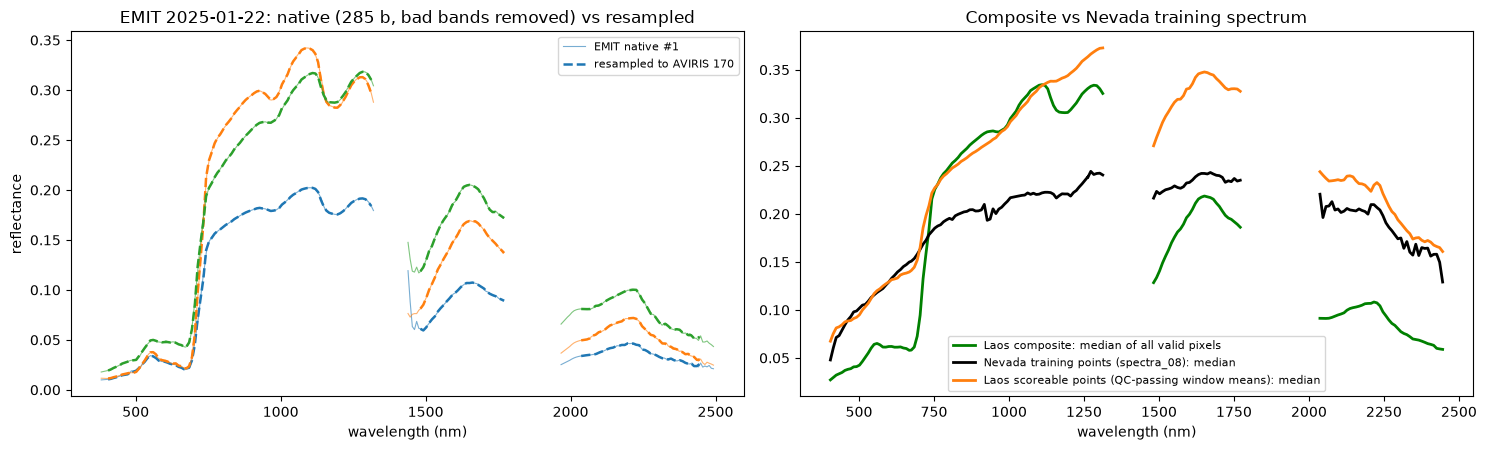

In [4]:
# QC plot: native EMIT spectra vs the same spectra resampled to the AVIRIS bands, and medians vs the Nevada training spectrum
wl_a, fw_a = lx.aviris_bands()
z = np.load(lx.gdir(SEL.key[0]) / "native_sample.npz"); spec_e, wl_e, good_e = z["spec"], z["wl"], z["good"]
fw_e = lx.emit_bands(lx.local_file(SEL.key[0], "RFL"))[1]
Wm, _ = lx.srf_matrix(wl_e, fw_e, good_e, wl_a, fw_a)
ok = (spec_e[:, good_e] > -1).all(1) & (spec_e[:, good_e] < 1.5).all(1); spec_e = spec_e[ok]; res = spec_e @ Wm
rng = np.random.default_rng(SEED); pick = rng.choice(len(spec_e), 3, replace=False)
data0 = ge.load_data()
nv_med = np.median(data0.spec[data0.tr_idx], 0)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
gap = lambda w, s: np.where(np.r_[False, np.diff(w) > 30], np.nan, s)      # break the line across removed water bands
for j, i in enumerate(pick):
    se = np.where(good_e, spec_e[i], np.nan)
    ax[0].plot(wl_e, se, c=f"C{j}", lw=.8, alpha=.6, label=f"EMIT native #{j + 1}" if j == 0 else None)
    ax[0].plot(wl_a, gap(wl_a, res[i]), c=f"C{j}", lw=1.8, ls="--", label="resampled to AVIRIS 170" if j == 0 else None)
ax[0].set(title="EMIT 2025-01-22: native (285 b, bad bands removed) vs resampled", xlabel="wavelength (nm)", ylabel="reflectance"); ax[0].legend(fontsize=8)
F = lx.open_cube()
smp_r, smp_c = np.where(F["valid"]); i = rng.choice(len(smp_r), 5000, replace=False)
comp = np.stack([np.asarray(F["cube170"][r, c]) for r, c in zip(smp_r[i], smp_c[i])])
ax[1].plot(wl_a, gap(wl_a, np.nanmedian(comp, 0)), c="g", lw=2, label="Laos composite: median of all valid pixels")
ax[1].plot(wl_a, gap(wl_a, nv_med), c="k", lw=2, label="Nevada training points (spectra_08): median")
_df = pd.read_csv(lx.INTERIM / "laos15_features.csv", usecols=["win_valid_frac"]); _sp = np.load(lx.INTERIM / "laos15_spectra.npz")["mean"]
ax[1].plot(wl_a, gap(wl_a, np.nanmedian(_sp[(_df.win_valid_frac >= 0.3).values], 0)), c="C1", lw=2, label="Laos scoreable points (QC-passing window means): median")
ax[1].set(title="Composite vs Nevada training spectrum", xlabel="wavelength (nm)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "laos15_spectra_qc.png", dpi=120); plt.show()

## 3. Composite (median ของวันที่ฟ้าเปิด)
granule ของวันเดียวกันถูกต่อกันก่อน (ไม่นับพื้นที่ซ้อนสองครั้ง) แล้วหา median รายพิกเซลข้ามวันที่ บันทึกเป็น
`data/interim/emit_laos_cube_x40.npy` (float32 memmap, H x W x 170) + `emit_laos_cube_x40_meta.json` และเปิดผ่าน `lx.open_cube()`
ซึ่งคืน dict แบบเดียวกับ `open_flight` (มี adapter `Cube224` ให้ `newline14.extract` ทำงานได้โดยไม่แก้โค้ด)

dates: ['2025-01-22', '2025-02-14', '2025-03-24', '2026-01-21', '2026-01-25', '2026-04-16', '2026-04-20']
composite reflectance QC: {"spike_share": 0.0, "482nm_p1_p50_p99": [0.019, 0.041, 0.107], "658nm_p1_p50_p99": [0.023, 0.06, 0.161], "860nm_p1_p50_p99": [0.169, 0.268, 0.357], "1651nm_p1_p50_p99": [0.109, 0.22, 0.428], "2197nm_p1_p50_p99": [0.047, 0.108, 0.287], "2326nm_p1_p50_p99": [0.031, 0.074, 0.228], "min": 0.0017557110404595733, "max": 1.2715051174163818, "valid_share_of_window": 0.9834738004829361}
clear dates per pixel (valid pixels):  {1: 45628, 2: 287433, 3: 468269, 4: 453631, 5: 230596, 6: 188888, 7: 10104}


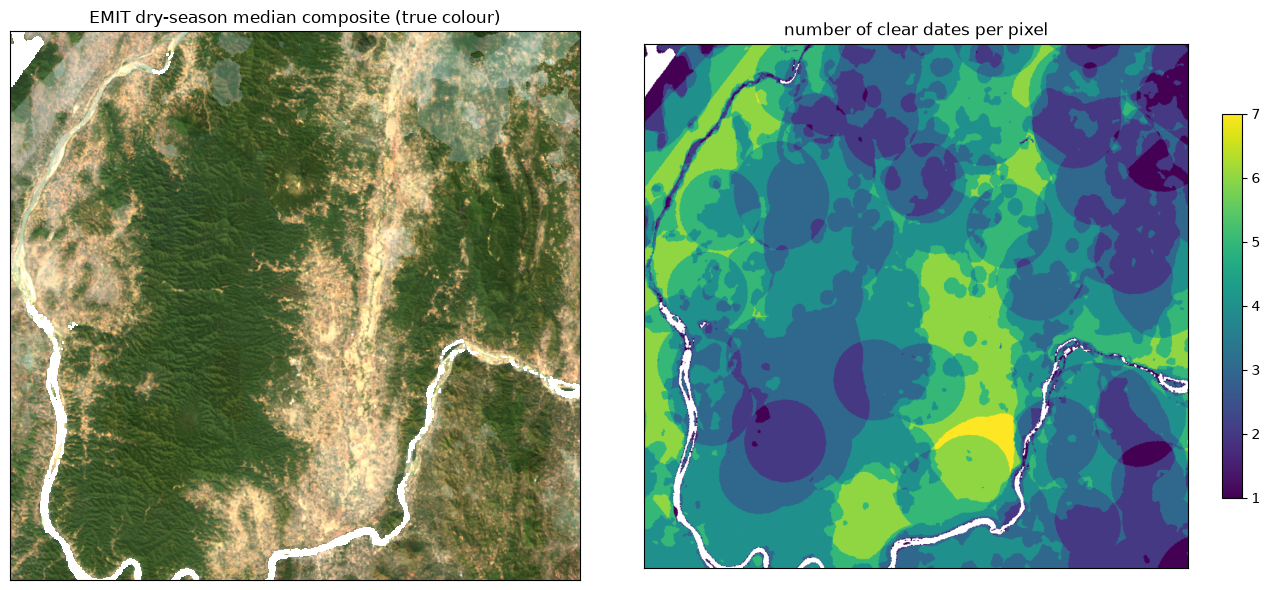

In [5]:
F = lx.composite(SEL)
QCC = lx.reflectance_qc_grid(F["cube170"])
print("dates:", F["meta"]["dates"]); print("composite reflectance QC:", json.dumps(QCC))
assert 0 <= QCC["482nm_p1_p50_p99"][1] < 1 and QCC["spike_share"] < 0.01
ns = F["nscenes"]
print("clear dates per pixel (valid pixels): ", pd.Series(ns[ns > 0]).value_counts().sort_index().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
rgb = np.stack([np.asarray(F["cube170"][::2, ::2, int(np.argmin(np.abs(wl_a - w)))]) for w in (650, 550, 470)], -1)
ax[0].imshow(np.clip(rgb / np.nanpercentile(rgb, 99), 0, 1)); ax[0].set_title("EMIT dry-season median composite (true colour)")
im = ax[1].imshow(np.where(ns > 0, ns, np.nan), cmap="viridis"); plt.colorbar(im, ax=ax[1], shrink=.7); ax[1].set_title("number of clear dates per pixel")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(OUT / "laos15_composite.png", dpi=110); plt.show()

## 4. Mask และพื้นที่ค้นหา
- พิกเซล QC แบบเดียวกับตอนฝึก: ตัดถ้า NIR(860) < 0.05, **NDVI > 0.35**, หรือค่าเพี้ยน (spike) และจุดหนึ่งจะถูกให้คะแนนก็ต่อเมื่อ
  หน้าต่าง 11x11 มีพิกเซลผ่าน QC >= 30% (`win_valid_frac >= 0.3`)
- น้ำ (แม่น้ำโขง): Water flag ของ EMIT ในวันที่เลือก (>= 50% ของวันที่ครอบคลุม) + NIR < 0.05
- **พื้นที่ค้นหา** = ความชัน 5.2-28.3 องศา (ความชันคำนวณแบบ NB08 บนกริด 90 m จาก Copernicus GLO-30 + `nan_mean(k=5)`) และไม่ใช่น้ำ
  (ไม่มี lithology ของลาว จึงไม่ตัดตะกอนน้ำพา/alluvium ด้วยธรณีวิทยา)

In [6]:
D = lx.dem_grid(); WAT = lx.water_grid(SEL); PM = lx.pixel_feature_maps(F)
gx, gy = lx.grid_xy(); UB = lx.box_mask(lx.USER_BOX); px_km2 = lx.RES ** 2 / 1e6
valid = F["valid"]; qc = PM["qc_ok"].astype(bool); water = np.nan_to_num(WAT) >= 0.5
slope_ok = (D["slope_s"] >= lx.SLOPE_WIN[0]) & (D["slope_s"] <= lx.SLOPE_WIN[1])
search_px = valid & slope_ok & ~water
MASKS = {
    "window_km2": float(lx.NY * lx.NX * px_km2),
    "share_window_emit_clear": float(valid.mean()), "share_userbox_emit_clear": float(valid[UB].mean()),
    "share_window_pixel_qc_ok (NDVI<=0.35 etc.)": float(qc.mean()), "share_userbox_pixel_qc_ok": float(qc[UB].mean()),
    "share_window_water": float(water.mean()),
    "ndvi_median_window": float(np.nanmedian(PM["NDVI"])), "ndvi_median_userbox": float(np.nanmedian(PM["NDVI"][UB])),
    "search_area_km2 (slope 5.2-28.3, not water, EMIT clear)": float(search_px.sum() * px_km2),
    "search_area_share_of_window": float(search_px.mean()),
}
pd.Series(MASKS).round(4)

window_km2                                                 2809.5121
share_window_emit_clear                                       0.9835
share_userbox_emit_clear                                      1.0000
share_window_pixel_qc_ok (NDVI<=0.35 etc.)                    0.0766
share_userbox_pixel_qc_ok                                     0.0024
share_window_water                                            0.0123
ndvi_median_window                                            0.6403
ndvi_median_userbox                                           0.7964
search_area_km2 (slope 5.2-28.3, not water, EMIT clear)    2250.1573
search_area_share_of_window                                   0.8009
dtype: float64

## 5. จุดกริด + feature (สูตร NB08)
- กริด 200 m (ทุก 5 พิกเซลของ 40.5 m เหมือนแผนที่ capture ของ `poc_figures`) ทั่วหน้าต่าง + ทุกพิกเซล 40.5 m ในกล่องของผู้ใช้
- `newline14.extract` (หน้าต่าง 11x11 ≈ 445 m) รันบน composite ผ่าน adapter + 36 คอลัมน์ `cr_*` (continuum removal แบบ NB08)
- จุดที่ให้คะแนนได้ = `win_valid_frac >= 0.3`; **ตัวหารของ rank-area = จุดกริดที่ให้คะแนนได้ในพื้นที่ค้นหา**

In [7]:
P = lx.build_points(F, D, WAT)
DF, SPEC = lx.extract_features(F, P)
DF["scored"] = DF.win_valid_frac >= ge.MIN_VALID_FRAC
DF["search_scored"] = DF.search & DF.scored
cnt = pd.crosstab(DF.set, [DF.search.rename("in search area"), DF.scored.rename("scoreable (win_valid_frac>=0.3)")], margins=True)
cell_km2 = (lx.STRIDE * lx.RES) ** 2 / 1e6
g_ = DF[DF.set == "grid"]
MASKS.update({"n_grid_points_valid": int(len(g_)), "n_grid_scored": int(g_.scored.sum()), "n_grid_search_scored": int(g_.search_scored.sum()),
              "share_grid_scored": float(g_.scored.mean()), "share_search_grid_scored": float(g_[g_.search].scored.mean()),
              "scored_search_area_km2": float(g_.search_scored.sum() * cell_km2),
              "n_userbox_pixels": int((DF.set == "userbox").sum()), "n_userbox_scored": int(DF[DF.set == "userbox"].scored.sum()),
              "userbox_win_valid_frac_max": float(DF[DF.set == "userbox"].win_valid_frac.max())})
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in MASKS.items() if k.startswith(("n_", "share_grid", "share_search", "scored", "userbox"))}, indent=1))
cnt

{
 "n_grid_points_valid": 67472,
 "n_grid_scored": 6386,
 "n_grid_search_scored": 1146,
 "share_grid_scored": 0.0946,
 "share_search_grid_scored": 0.0208,
 "scored_search_area_km2": 46.9932,
 "n_userbox_pixels": 26316,
 "n_userbox_scored": 0,
 "userbox_win_valid_frac_max": 0.157
}


in search area                  False         True          All
scoreable (win_valid_frac>=0.3) False  True  False  True       
set                                                            
grid                             7253  5240  53833  1146  67472
userbox                            40     0  26276     0  26316
All                              7293  5240  80109  1146  93788

**กล่องของผู้ใช้ให้คะแนนไม่ได้เลย** ด้วยสูตรที่ใช้ฝึก: พิกเซลในกล่องมี NDVI มัธยฐาน ~0.8 (ป่าทึบ/สวน) ผ่าน QC (NDVI <= 0.35) เพียง
~0.2% และไม่มีหน้าต่าง 11x11 ใดที่มีพิกเซลผ่าน QC ถึง 30% โมเดลทั้งหมดถูกฝึกบน "หินโผล่/ดินเปลือย" เท่านั้น การผ่อน QC เพื่อให้คะแนน
เรือนยอดไม้จะเป็นการใช้นอกโดเมนโดยสิ้นเชิง (และเท่ากับเปลี่ยนสูตร feature) จึง **ไม่ทำ** ส่วนที่ทำได้คือแผนที่ทั้งหน้าต่าง (เฉพาะบริเวณ
ที่ดินเปิดโล่ง) และภาพซูมกล่องที่แสดง NDVI / QC / จุดกริดรอบ ๆ ที่ให้คะแนนได้

## 6. Patch 24x24 + DINOv2 embedding
patch ใช้นิยามช่องสัญญาณเดียวกับ `newline14.build_patches` (rgb, feat8, CR-SWIR 36) อ่านจาก composite; view ของ DINOv2 ใช้
`newline14.dino_view_transform()` ซึ่งคำนวณเปอร์เซ็นไทล์และ CR-PCA จาก **patch ของเที่ยวบินฝึก Nevada** (ไม่ fit ใหม่กับลาว);
`Dino().embed_views` บน GPU (fp16, batch 32) แล้วปล่อยหน่วยความจำ

In [8]:
rows = np.where(DF.scored.values)[0]
lx.build_patches(F, DF, rows, lx.PROC / "patches_laos15")
PL = nl.load_patch_dir(lx.PROC / "patches_laos15")
E_l, einfo = lx.embed_patches(lx.PROC / "patches_laos15", lx.PROC / "dino_emb_laos15.npz")
assert np.array_equal(PL["idx"], rows) and np.isfinite(E_l).all()
print(f"patches {len(rows)} (valid pixel share {PL['valid'].mean():.1%}); embeddings {E_l.shape}; {einfo}")

patches 6386 (valid pixel share 48.6%); embeddings (6386, 4608); {'cr_pca_evr': [0.7231868505477905, 0.08838263899087906, 0.05738789215683937], 'embed_s': 160.8, 'device': 'cuda'}


## 7. ให้คะแนนด้วยโมเดลแช่แข็ง (M0, M2, M3)
ตามรูปแบบของ NB14 cell 14-16: `df_all` = แถว features_08 (ลำดับเดียวกับ harness) ต่อด้วยแถวลาว, `E_all` = embedding ฝึกของ NB12 +
embedding ลาว, แล้ว `MODELS = make_frozen_models(df_all, y_all, data.tr_ctrl_idx, E_all=E_all)` และ `MODELS[k](data.tr_idx, laos_idx)`
**ครั้งเดียวต่อโมเดล** บนทุกแถวลาวที่ให้คะแนนได้ จากนั้นแปลงเป็น rank-area เทียบกับจุดกริดในพื้นที่ค้นหาของลาวเอง
(rank-area 0.10 = อยู่ใน 10% บนของพื้นที่ค้นหา) เพิ่มตัวจัดอันดับหลอก 2 ตัวเพื่อเทียบ: **NDVI-only** (NDVI ต่ำ = อันดับสูง) และ
**albedo-only** (สว่าง = อันดับสูง)

In [9]:
L = DF.iloc[rows].reset_index(drop=True)
S, data, E_tr, y_tr = lx.frozen_scores(L, E_l, MODELS_USED)
L = pd.concat([L, S], axis=1)
L["NDVI_only"] = -L.s2_NDVI; L["albedo_only"] = L.albedo
RANKERS = MODELS_USED + ["NDVI_only", "albedo_only"]
L = lx.add_rank_area(L, RANKERS, L.search_scored.values)
ref = L.search_scored.values
for k in MODELS_USED:
    top = L[ref & (L[f"ra_{k}"] <= 0.10)]
    print(f"{NAMES[k]}: score range {L[k].min():.3f}..{L[k].max():.3f}; top-10% cells in search area: {len(top)} (~{len(top) * cell_km2:.1f} km2)")
print("Spearman between model scores over the scored search area:")
L.loc[ref, MODELS_USED].corr("spearman").round(3)

  M0: 6386 Laos rows scored in 0s


  M2: 6386 Laos rows scored in 5s


  M3: 6386 Laos rows scored in 0s


M0 baseline LR HS+p90: score range 0.000..0.992; top-10% cells in search area: 114 (~4.7 km2)
M2 rank ensemble LDA+LR+LGBM: score range 0.025..0.996; top-10% cells in search area: 114 (~4.7 km2)
M3 DINOv2 late fusion w=0.5: score range -7.916..3.045; top-10% cells in search area: 114 (~4.7 km2)
Spearman between model scores over the scored search area:


,M0,M2,M3
M0,1.000,-0.248,0.964
M2,-0.248,1.000,-0.241
M3,0.964,-0.241,1.000


## 8. Domain shift (หัวใจของ notebook นี้)
เทียบ 61 feature (ALL_TAB+CR) ของจุดลาวที่ให้คะแนนได้กับจุดฝึก Nevada (`data.tr_idx`: ทองคำ 208 + background 1,004):
มัธยฐาน, การเลื่อนในหน่วย sd ของ Nevada, และสัดส่วนจุดลาวที่อยู่นอกช่วง 1-99% ของ Nevada

{
 "median_abs_shift_sd": 0.877,
 "n_features_laos_median_outside_nevada_1_99": 13,
 "mean_share_laos_outside_1_99": 0.243,
 "n_features_over_50pct_outside": 13,
 "share_laos_rows_any_feature_outside_1_99": 1.0
}


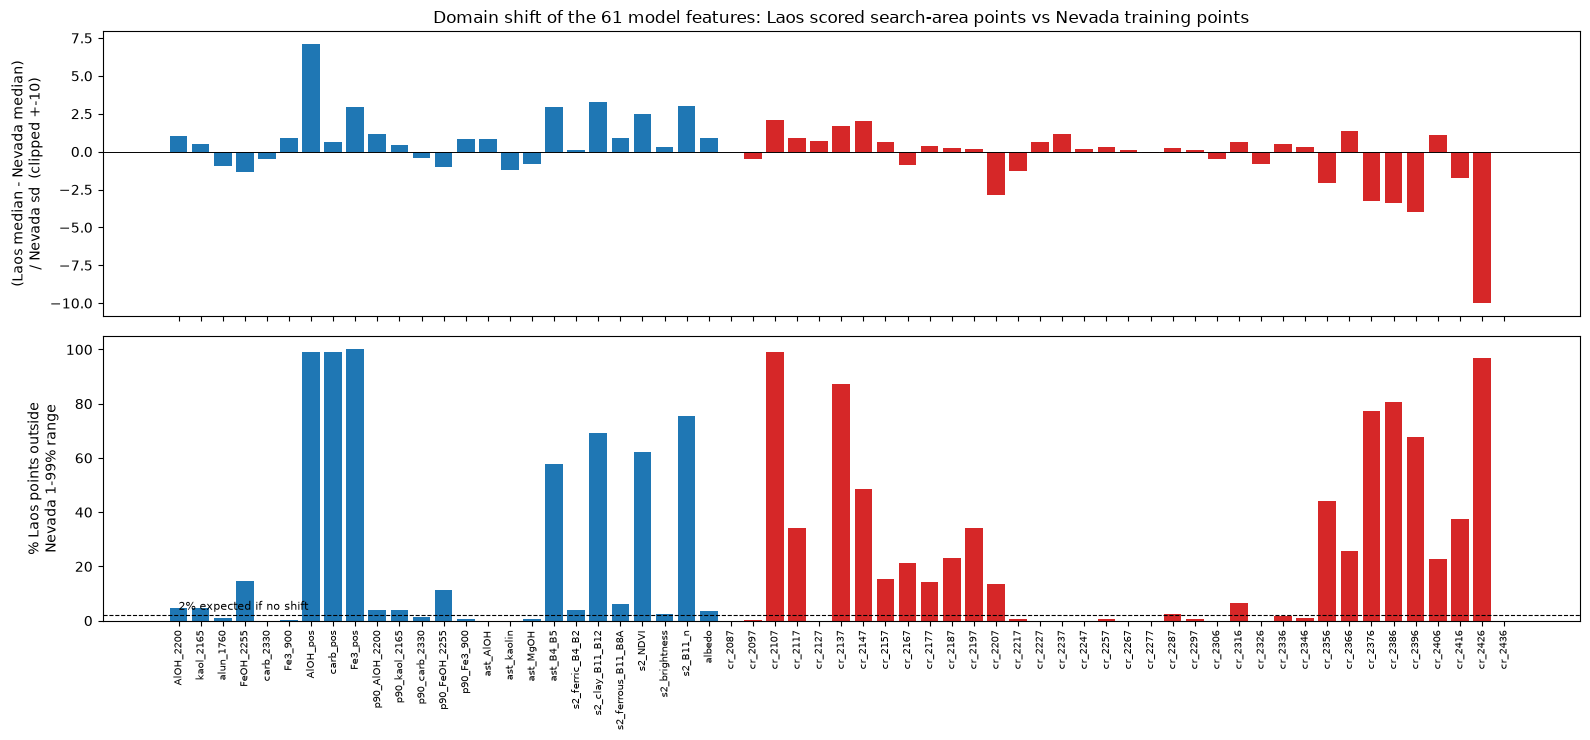

,feature,nevada_train_median,nevada_train_sd,nevada_p1,nevada_p99,laos_median,shift_in_train_sd,laos_below_p1,laos_above_p99,laos_outside_1_99,laos_n_finite,nevada_n_finite,laos_outside_1_99_all_scored
8,Fe3_pos,932.678,1.497,926.293,934.045,937.085,2.944,0.000,1.000,1.000,77,93,0.994
6,AlOH_pos,2195.360,1.230,2193.550,2199.465,2204.080,7.088,0.000,0.992,0.992,609,212,0.981
27,cr_2107,0.979,0.006,0.961,0.984,0.991,2.091,0.000,0.990,0.990,1146,1212,0.907
7,carb_pos,2342.442,5.395,2316.018,2343.828,2345.865,0.634,0.000,0.990,0.990,1027,1066,0.992
59,cr_2426,1.000,0.000,1.000,1.000,0.984,-363.701,0.970,0.000,0.970,1146,1212,0.925
30,cr_2137,0.982,0.011,0.955,0.999,1.000,1.686,0.000,0.873,0.873,1146,1212,0.949
55,cr_2386,0.974,0.012,0.947,0.998,0.934,-3.421,0.805,0.000,0.805,1146,1212,0.534
54,cr_2376,0.965,0.012,0.938,0.994,0.926,-3.271,0.771,0.000,0.771,1146,1212,0.529
23,s2_B11_n,1.366,0.109,1.098,1.579,1.693,2.999,0.019,0.737,0.757,1146,1212,0.741
19,s2_clay_B11_B12,1.159,0.100,0.918,1.438,1.484,3.258,0.000,0.692,0.692,1146,1212,0.582


In [10]:
COLS61 = ge.FEATURE_SETS["ALL_TAB+CR"]; assert len(COLS61) == 61
d_tr = data.df.iloc[data.tr_idx]
DS = lx.domain_shift_table(d_tr, L[L.search_scored], COLS61)
DS_all = lx.domain_shift_table(d_tr, L, COLS61)
DS["laos_outside_1_99_all_scored"] = DS_all.laos_outside_1_99.values
DS.to_csv(OUT / "laos15_domain_shift.csv", index=False)
SHIFT = {"median_abs_shift_sd": float(DS.shift_in_train_sd.abs().median()),
         "n_features_laos_median_outside_nevada_1_99": int(((DS.laos_median < DS.nevada_p1) | (DS.laos_median > DS.nevada_p99)).sum()),
         "mean_share_laos_outside_1_99": float(DS.laos_outside_1_99.mean()),
         "n_features_over_50pct_outside": int((DS.laos_outside_1_99 > 0.5).sum()),
         "share_laos_rows_any_feature_outside_1_99": float(np.mean(np.any([(L.loc[L.search_scored, c] < DS.nevada_p1[i]) | (L.loc[L.search_scored, c] > DS.nevada_p99[i])
                                                                           for i, c in enumerate(DS.feature)], axis=0)))}
print(json.dumps({k: round(v, 3) for k, v in SHIFT.items()}, indent=1))
fig, ax = plt.subplots(2, 1, figsize=(16, 7.5), sharex=True)
xx = np.arange(len(DS)); col = ["C3" if f.startswith("cr_") else "C0" for f in DS.feature]
ax[0].bar(xx, DS.shift_in_train_sd.clip(-10, 10), color=col); ax[0].axhline(0, c="k", lw=.7)
ax[0].set_ylabel("(Laos median - Nevada median)\n/ Nevada sd  (clipped +-10)"); ax[0].set_title("Domain shift of the 61 model features: Laos scored search-area points vs Nevada training points")
ax[1].bar(xx, DS.laos_outside_1_99 * 100, color=col); ax[1].axhline(2, c="k", ls="--", lw=.8); ax[1].text(0, 4, "2% expected if no shift", fontsize=8)
ax[1].set_ylabel("% Laos points outside\nNevada 1-99% range"); ax[1].set_xticks(xx); ax[1].set_xticklabels(DS.feature, rotation=90, fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "laos15_domain_shift.png", dpi=120); plt.show()
DS.sort_values("laos_outside_1_99", ascending=False).head(15).round(3)

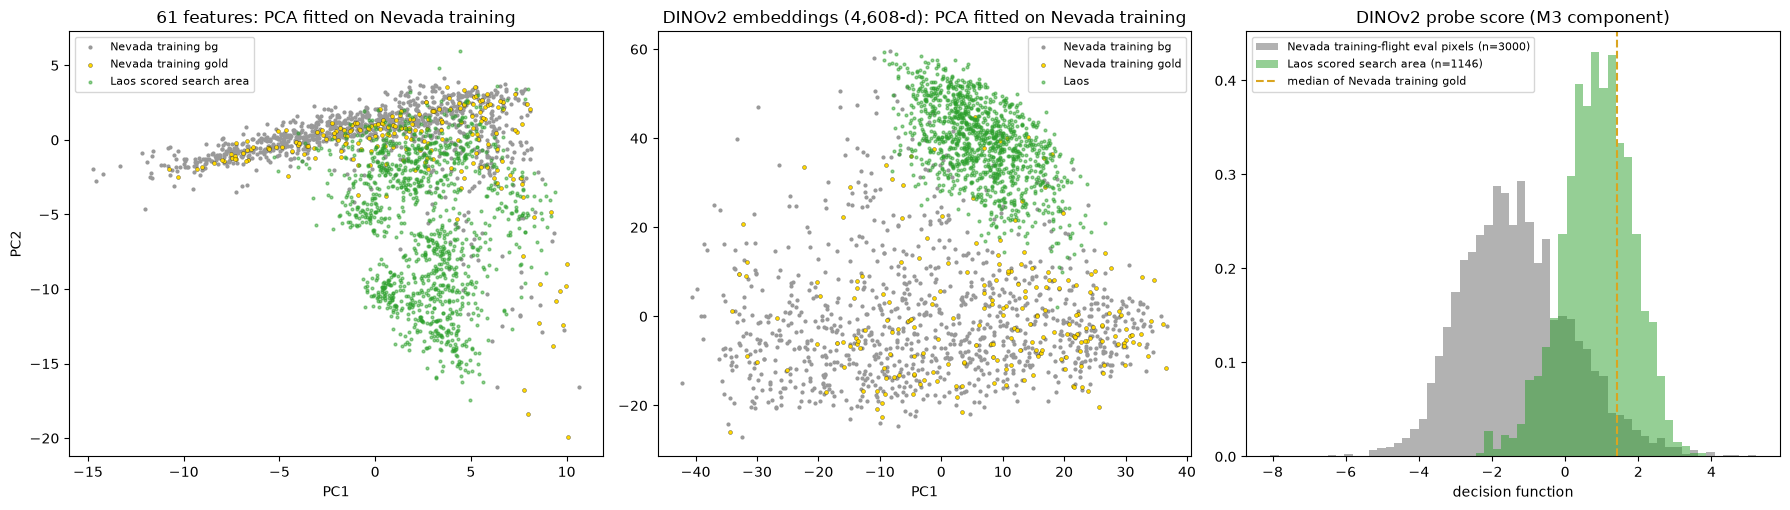

{
 "pca61_share_laos_beyond_nevada_p99_mahal": 0.09336823734729494,
 "dino_pca_share_laos_beyond_nevada_p99_mahal": 0.2006980802792321,
 "probe_median_nevada_eval": -1.4342625141143799,
 "probe_median_laos": 0.9133365154266357,
 "probe_median_nevada_train_gold": 1.4284065961837769,
 "pca61_explained_var": [
  0.427,
  0.119
 ]
}


In [11]:
# 2-D PCA of the 61 features (imputer + scaler + PCA fitted on Nevada training rows only) and of the DINOv2 embeddings;
# probe score distribution (the M3 probe, refit identically on the training rows - diagnostic only) Laos vs Nevada eval pixels
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
pca61 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PCA(2, random_state=SEED)).fit(d_tr[COLS61].values)
Ztr = pca61.transform(d_tr[COLS61].values); Zl = pca61.transform(L.loc[L.search_scored, COLS61].values)
P13 = pt.load_patches(); z12 = np.load(lx.PROC / "dino_emb_12.npz")
E13 = np.concatenate([z12[f"{v}_224"] for v in nl.VIEWS], 1); row13 = {int(i): j for j, i in enumerate(P13["idx"])}
ev_rows = np.array([row13[i] for i in P13["idx"] if data.df.flight.values[i] == "train" and data.df.set.values[i] == "eval"])
pcaE = make_pipeline(StandardScaler(), PCA(2, random_state=SEED)).fit(E_tr)
probe = make_pipeline(StandardScaler(), LogisticRegression(C=0.001, max_iter=3000, class_weight="balanced")).fit(E_tr, y_tr)
s_tr, s_ev, s_l = probe.decision_function(E_tr), probe.decision_function(E13[ev_rows]), probe.decision_function(E_l[L.search_scored.values])
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
ax[0].scatter(*Ztr[y_tr == 0].T, s=4, c="0.6", label="Nevada training bg"); ax[0].scatter(*Ztr[y_tr == 1].T, s=8, c="gold", ec="k", lw=.2, label="Nevada training gold")
ax[0].scatter(*Zl.T, s=4, c="C2", alpha=.5, label="Laos scored search area"); ax[0].set(title="61 features: PCA fitted on Nevada training", xlabel="PC1", ylabel="PC2"); ax[0].legend(fontsize=8)
Etr2, El2 = pcaE.transform(E_tr), pcaE.transform(E_l[L.search_scored.values])
ax[1].scatter(*Etr2[y_tr == 0].T, s=4, c="0.6", label="Nevada training bg"); ax[1].scatter(*Etr2[y_tr == 1].T, s=8, c="gold", ec="k", lw=.2, label="Nevada training gold")
ax[1].scatter(*El2.T, s=4, c="C2", alpha=.5, label="Laos"); ax[1].set(title="DINOv2 embeddings (4,608-d): PCA fitted on Nevada training", xlabel="PC1"); ax[1].legend(fontsize=8)
bins = np.linspace(min(s_ev.min(), s_l.min()), max(s_ev.max(), s_l.max()), 60)
ax[2].hist(s_ev, bins, density=True, alpha=.5, color="0.4", label=f"Nevada training-flight eval pixels (n={len(s_ev)})")
ax[2].hist(s_l, bins, density=True, alpha=.5, color="C2", label=f"Laos scored search area (n={len(s_l)})")
ax[2].axvline(np.median(s_tr[y_tr == 1]), c="goldenrod", ls="--", label="median of Nevada training gold"); ax[2].set(title="DINOv2 probe score (M3 component)", xlabel="decision function"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "laos15_pca_embedding_shift.png", dpi=115); plt.show()
# distance in Nevada-training-sd units in both PCA spaces
def mahal_share(Z_ref, Z_new, q=99):
    c = Z_ref.mean(0); S = np.cov(Z_ref.T); Si = np.linalg.inv(S)
    d = lambda Z: np.sqrt(np.einsum("ij,jk,ik->i", Z - c, Si, Z - c))
    return float((d(Z_new) > np.percentile(d(Z_ref), q)).mean())
SHIFT.update({"pca61_share_laos_beyond_nevada_p99_mahal": mahal_share(Ztr, Zl), "dino_pca_share_laos_beyond_nevada_p99_mahal": mahal_share(Etr2, El2),
              "probe_median_nevada_eval": float(np.median(s_ev)), "probe_median_laos": float(np.median(s_l)), "probe_median_nevada_train_gold": float(np.median(s_tr[y_tr == 1])),
              "pca61_explained_var": pca61[-1].explained_variance_ratio_.round(3).tolist()})
print(json.dumps({k: SHIFT[k] for k in list(SHIFT)[-6:]}, indent=1))

### Shortcut check: คะแนนตามความเขียว / ความสว่าง / ภูมิประเทศหรือเปล่า
Spearman ระหว่างคะแนนแต่ละโมเดลกับ NDVI, albedo, ความชัน, ความสูง, ระยะห่างจากแหล่งน้ำ บนจุดในพื้นที่ค้นหาที่ให้คะแนนได้
(แบบ NB12 cell 26) และเทียบกับตัวจัดอันดับหลอก NDVI-only / albedo-only; พร้อมสัดส่วนเซลล์ 10% บนที่อยู่ห่างแม่น้ำ <= 1 km
(พิกเซลที่ผ่าน QC จำนวนมากคือตลิ่ง/หาดทรายแม่น้ำโขงที่โผล่ในฤดูแล้ง)

In [12]:
Ls = L[L.search_scored]
SC = pd.DataFrame({k: {c: spearmanr(Ls[k], Ls[c], nan_policy="omit")[0] for c in ["s2_NDVI", "albedo", "s2_brightness", "slope", "elev"]} for k in RANKERS}).T
SC["vs NDVI_only"] = [spearmanr(Ls[k], Ls.NDVI_only)[0] for k in RANKERS]; SC["vs albedo_only"] = [spearmanr(Ls[k], Ls.albedo_only)[0] for k in RANKERS]
# distance to water (Mekong + tributaries, EMIT water flag): exposed river banks / sand bars dominate the QC-passing pixels
from scipy import ndimage as ndi
DW = (ndi.distance_transform_edt(~water) * lx.RES).astype("float32")
L["dist_water_m"] = DW[L.r.values, L.c.values]; Ls = L[L.search_scored]
SC["dist_water_m"] = [spearmanr(Ls[k], Ls.dist_water_m)[0] for k in RANKERS]
SC.to_csv(OUT / "laos15_shortcut_corr.csv")
near = Ls.dist_water_m <= 1000
NEARW = {"share_search_scored_within_1km_of_water": float(near.mean())}
for k in RANKERS: NEARW[f"share_top10_{k}_within_1km_of_water"] = float(near[Ls[f"ra_{k}"] <= .10].mean())
print(json.dumps({k: round(v, 3) for k, v in NEARW.items()}, indent=1))
SC.round(3)

{
 "share_search_scored_within_1km_of_water": 0.298,
 "share_top10_M0_within_1km_of_water": 0.07,
 "share_top10_M2_within_1km_of_water": 0.333,
 "share_top10_M3_within_1km_of_water": 0.105,
 "share_top10_NDVI_only_within_1km_of_water": 0.895,
 "share_top10_albedo_only_within_1km_of_water": 0.07
}


,s2_NDVI,albedo,s2_brightness,slope,elev,vs NDVI_only,vs albedo_only,dist_water_m
M0,0.229,0.065,0.066,-0.133,-0.020,-0.229,0.065,0.102
M2,-0.103,-0.008,-0.015,0.089,0.076,0.103,-0.008,0.152
M3,0.244,0.051,0.053,-0.125,0.026,-0.244,0.051,0.153
NDVI_only,-1.000,-0.568,-0.530,0.048,-0.447,1.000,-0.568,-0.527
albedo_only,0.568,1.000,0.992,-0.099,0.342,-0.568,1.000,0.403


### EMIT L2B MIN cross-check (ทางเลือก, granule 2025-01-22 เท่านั้น)
EMIT มีแผนที่ชนิดแร่ของตัวเอง (group 1 = แร่เหล็ก ~1 µm, group 2 = แร่ 2 µm; id 0 = ไม่พบ) เทียบว่า feature ของเรา
(AlOH_2200, kaol_2165, Fe3_900 แบบ per-pixel) สูงกว่าในพิกเซลที่ EMIT ระบุแร่กลุ่มเดียวกันหรือไม่ (AUC) ใช้เฉพาะพิกเซลที่ผ่าน QC ของเรา

In [13]:
MINX = {}
mk = SEL.key[0]
if sorted(lx.gdir(mk).glob("EMIT_L2B_MIN_001_*.nc")):
    Mn = lx.min_grid(mk); names = Mn["names"]
    fam = lambda pats: np.array([any(p in n.lower() for p in pats) for n in names])
    FAM = {"kaolinite (g2)": ("g2", fam(["kaol", "halloy", "dickite"]), "kaol_2165"),
           "2.2 um Al-OH: muscovite/illite/smectite/kaolinite (g2)": ("g2", fam(["musc", "illite", "sericite", "mont", "smect", "kaol"]), "AlOH_2200"),
           "Fe3+ goethite/hematite/jarosite/ferrihydrite (g1)": ("g1", fam(["goeth", "hemat", "jaros", "ferrihyd", "lepido", "schwert"]), "Fe3_900")}
    m_ok = PM["qc_ok"].astype(bool) & np.isfinite(Mn["g1_id"])
    rows_ = []
    for lab, (grp, isfam, feat) in FAM.items():
        ids = Mn[f"{grp}_id"]; idx_ok = np.where(m_ok)
        idv = ids[idx_ok].astype(int); present = (idv > 0) & isfam[np.clip(idv, 0, len(names) - 1)]
        f = PM[feat][idx_ok]; good = np.isfinite(f)
        auc = ge._auc(present[good].astype(int), f[good]) if present[good].any() else np.nan
        rows_.append({"EMIT family": lab, "our feature": feat, "n_qc_pixels": int(good.sum()), "share_EMIT_detects": float(present[good].mean()),
                      "AUC our feature (EMIT detect vs not)": auc,
                      "median feature | detect": float(np.nanmedian(f[good][present[good]])) if present[good].any() else np.nan,
                      "median feature | no detect": float(np.nanmedian(f[good][~present[good]]))})
    MINX = pd.DataFrame(rows_)
    top_g2 = pd.Series(Mn["g2_id"][m_ok & (Mn["g2_id"] > 0)].astype(int)).value_counts().head(8)
    print("share of QC-ok pixels with an EMIT group-2 / group-1 detection:", round(float((Mn["g2_id"][m_ok] > 0).mean()), 3), round(float((Mn["g1_id"][m_ok] > 0).mean()), 3))
    print("most frequent EMIT group-2 detections (id > 0) on QC-ok pixels:", {str(names[i]): int(c) for i, c in top_g2.items()})
    MINX.to_csv(OUT / "laos15_emit_min_crosscheck.csv", index=False)
else:
    print("no L2B MIN file downloaded - cross-check skipped")
MINX.round(3) if len(MINX) else None

share of QC-ok pixels with an EMIT group-2 / group-1 detection: 0.445 0.281
most frequent EMIT group-2 detections (id > 0) on QC-ok pixels: {'Plywood GDS365 Fresh Pine W1R1Fa': 13966, 'Grass_dry+0.17%Na-Mont AMX35 W1R1Ba AREF': 9790, 'Clintonite NMNH126553 W1R1Bc': 4677, 'Calcite.33+Kaol.33+Mus AMXr2 W1R1Ba': 3316, 'Muscovite GDS113 Ruby W1R1Bb splib06 3348': 3247, 'Calcite.7+Kaolwxl.3 AMX9 W1R1Ba': 2649, 'Paragonite GDS109 W1R1Ba': 2584, 'Mascagnite GDS65.b (fr) W1R1Ba': 1530}


,EMIT family,our feature,n_qc_pixels,share_EMIT_detects,AUC our feature (EMIT detect vs not),median feature | detect,median feature | no detect
0,kaolinite (g2),kaol_2165,126514,0.068,0.542,-0.003,-0.005
1,2.2 um Al-OH: muscovite/illite/smectite/kaolin...,AlOH_2200,126514,0.182,0.833,0.033,-0.021
2,Fe3+ goethite/hematite/jarosite/ferrihydrite (g1),Fe3_900,126514,0.263,0.829,0.016,-0.004


## 9. ตรวจกับจุดทอง MRDS ในหน้าต่าง (เชิงพรรณนาเท่านั้น)
พิกัด MRDS ของลาวปัดเศษ ~1 arc-minute (±1 km) และเกือบทั้งหมดเป็นเพียง `Occurrence` (มีแค่ Sanakham-I ที่เป็น Producer) จึงใช้
**คะแนนสูงสุดของจุดกริดที่ให้คะแนนได้ภายในรัศมี 1.5 km** แล้วดู rank-area ของค่านั้น
ข้อควรระวัง: ค่าสูงสุดจากจุดหลายสิบจุดย่อมอยู่อันดับสูงเสมอ จึงคำนวณสถิติเดียวกันที่ **ตำแหน่งสุ่ม 2,000 จุด** ในหน้าต่าง (เงื่อนไขเดียวกัน:
มีจุดให้คะแนนได้ในรัศมีอย่างน้อย 1 จุด) เป็นเส้นฐาน และรายงาน `null_beats` = สัดส่วนตำแหน่งสุ่มที่ได้ค่าดีเท่าหรือดีกว่าจุดทอง
(ยิ่งน้อยยิ่งดีกว่าโอกาส) n ประมาณ 6-7 จุด: **bootstrap CI ไม่มีความหมาย** จึงไม่คำนวณ

In [14]:
SITES = lx.mrds_window()
T_SITES, NULL, NULLD = lx.site_ranks(L, SITES, RANKERS, radius=1500, centres_xy=DF.loc[DF.set == "grid", ["x", "y"]].values)
T_SITES = SITES[["site_name", "country", "latitude", "longitude", "x", "y", "commods", "in_user_box"]].merge(T_SITES, on="site_name")
rr_, cc_ = np.clip(((lx.WINDOW["ymax"] - T_SITES.y) // lx.RES).astype(int), 0, lx.NY - 1), np.clip(((T_SITES.x - lx.WINDOW["xmin"]) // lx.RES).astype(int), 0, lx.NX - 1)
T_SITES["dist_water_m"] = DW[rr_, cc_]
T_SITES.to_csv(OUT / "laos15_gold_points.csv", index=False)
gold = T_SITES[T_SITES.gold]; ranked = gold[gold.n_grid_in_radius > 0]
REC = {}
for k in RANKERS:
    v = ranked[f"ra_max1500_{k}"]
    REC[k] = {"n_gold_in_window": int(len(gold)), "n_gold_rankable": int(len(ranked)),
              "recall@10 (max in 1.5 km)": f"{int((v <= .10).sum())}/{len(ranked)}", "recall@20 (max in 1.5 km)": f"{int((v <= .20).sum())}/{len(ranked)}",
              "null: random location in top 10%": round(NULL[k]["null_in_top10"], 3), "null: in top 20%": round(NULL[k]["null_in_top20"], 3),
              "median null_beats of gold (0.5 = chance)": round(float(ranked[f"null_beats_{k}"].median()), 3)}
REC = pd.DataFrame(REC).T
print("gold sites with no scoreable 200 m grid point within 1.5 km (vegetation / cloud):", list(gold.loc[gold.n_grid_in_radius == 0, "site_name"]))
show = ["site_name", "commods", "dev_stat", "dep_type", "dist_water_m", "n_grid_in_radius", "n_search_in_radius"] + [f"ra_max1500_{k}" for k in RANKERS] + [f"null_beats_{k}" for k in MODELS_USED]
display(T_SITES[show].round(3))
REC

gold sites with no scoreable 200 m grid point within 1.5 km (vegetation / cloud): ['Houei King', 'Man Khouan']


,site_name,commods,dev_stat,dep_type,dist_water_m,n_grid_in_radius,n_search_in_radius,ra_max1500_M0,ra_max1500_M2,ra_max1500_M3,ra_max1500_NDVI_only,ra_max1500_albedo_only,null_beats_M0,null_beats_M2,null_beats_M3
0,Don Men,"Gold, Tin",Occurrence,NaN,2715.614990,1,1,0.225,0.684,0.170,0.526,0.484,0.306,0.382,0.267
1,Houei King,Gold,Occurrence,Placer,2728.270020,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Man Khouan,Gold,Occurrence,Placer,12955.252930,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Pak Lay,Gold,Occurrence,NaN,202.500000,117,14,0.010,0.033,0.029,0.002,0.122,0.083,0.093,0.140
4,Pak Leng,Gold,Occurrence,NaN,57.276001,18,5,0.278,0.032,0.239,0.023,0.067,0.322,0.086,0.312
5,Sanakham-I,Gold,Producer,NaN,2850.577881,76,10,0.003,0.144,0.001,0.199,0.006,0.032,0.260,0.018
6,Sanakham-Ii,Gold,Occurrence,Placer,0.000000,67,0,0.260,0.072,0.257,0.051,0.009,0.318,0.172,0.320
7,Huai Muang Mine,Manganese,Past Producer,NaN,6294.722168,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Huai Pang,Manganese,Occurrence,Vein,128.072006,53,7,0.071,0.003,0.329,0.000,0.411,0.195,0.014,0.347
9,Sanakham,Graphite,Occurrence,NaN,6275.278809,29,2,0.044,0.138,0.029,0.227,0.007,0.161,0.256,0.140


,n_gold_in_window,n_gold_rankable,recall@10 (max in 1.5 km),recall@20 (max in 1.5 km),null: random location in top 10%,null: in top 20%,median null_beats of gold (0.5 = chance)
M0,7,5,2/5,2/5,0.222,0.291,0.306
M2,7,5,3/5,4/5,0.211,0.297,0.172
M3,7,5,2/5,3/5,0.22,0.282,0.267
NDVI_only,7,5,3/5,4/5,0.102,0.181,0.088
albedo_only,7,5,3/5,4/5,0.223,0.281,0.208


## 10. แผนที่, GeoTIFF, KML
- แผนที่ทั้งหน้าต่างของ M3 / M2 / M0: แดง = 10% บนของพื้นที่ค้นหาที่ให้คะแนนได้, ส้ม = 10-20%, เทา = ที่เหลือ; จุดฟ้าอ่อน = ให้คะแนนได้แต่
  อยู่นอกช่วงความชัน (ส่วนใหญ่ที่ราบ/นา); ไม่มีสี = ไม่ผ่าน QC (พืชคลุม NDVI > 0.35, เมฆ); น้ำ = เทาเข้ม; ดาว = จุดทอง MRDS; สามเหลี่ยม = แร่อื่น
- ภาพซูมกล่องผู้ใช้ที่ 40.5 m, แผนที่ feature แร่ (AlOH_2200, kaol_2165, Fe3_900, NDVI) ทั้งหน้าต่าง

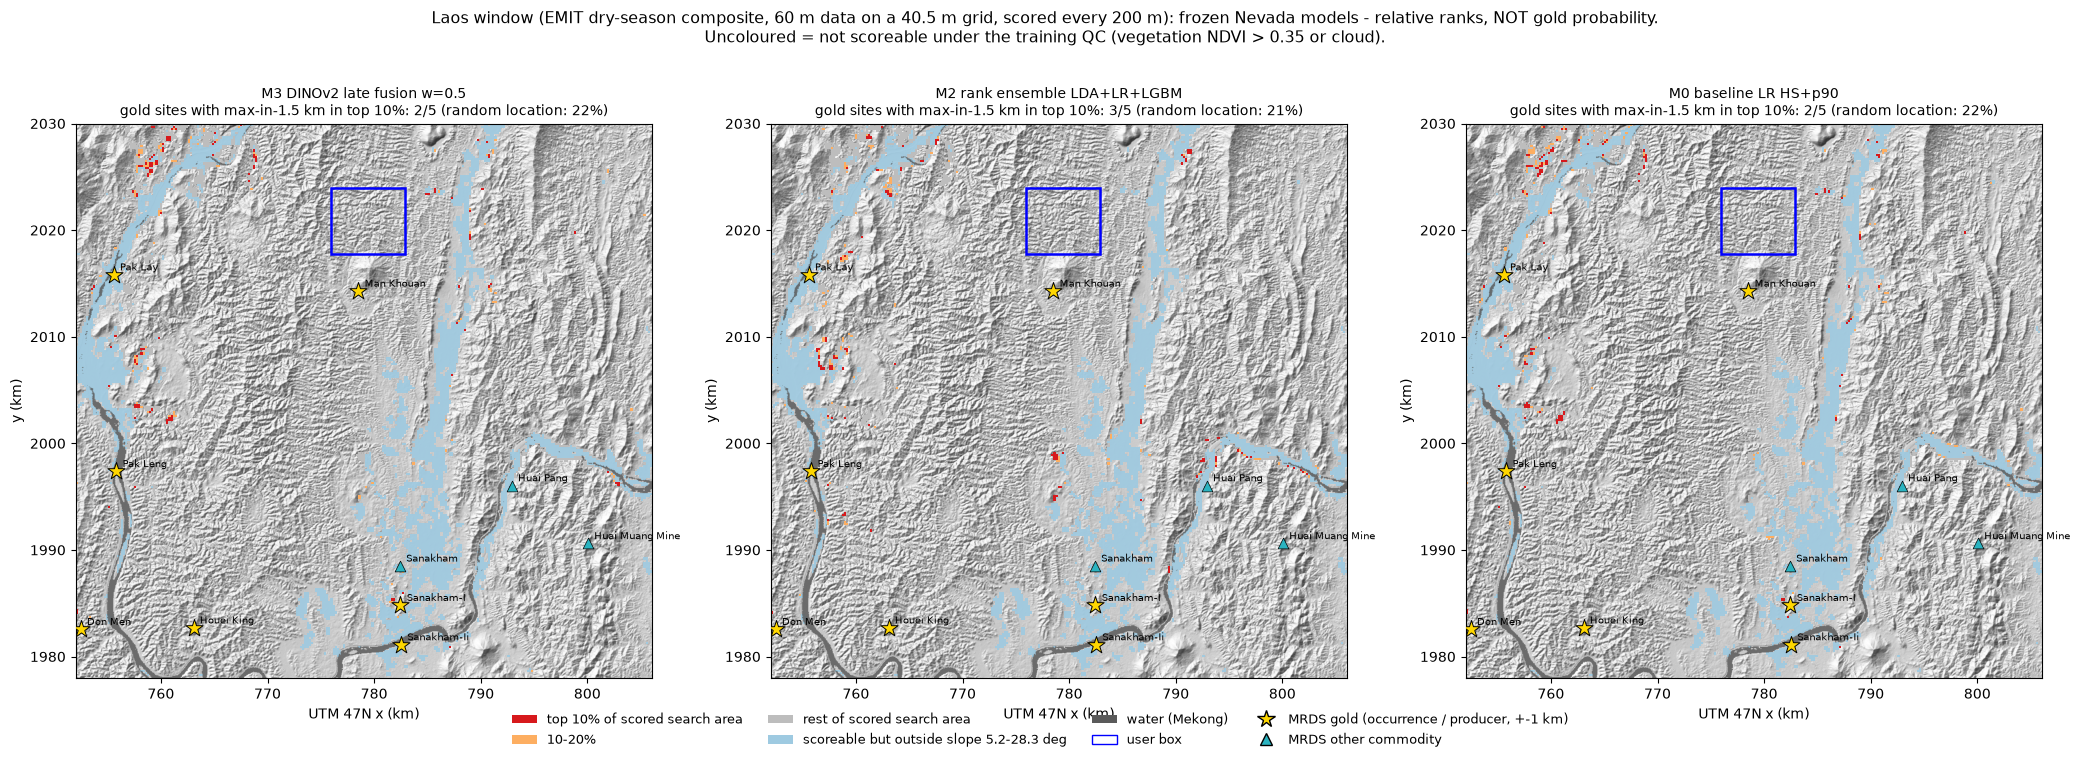

In [15]:
ZONE = ListedColormap(["#bdbdbd", "#fdae61", "#d7191c"])
HS = lx.hillshade(D["elev"])
EXT = [lx.WINDOW["xmin"] / 1e3, (lx.WINDOW["xmin"] + lx.NX * lx.RES) / 1e3, (lx.WINDOW["ymax"] - lx.NY * lx.RES) / 1e3, lx.WINDOW["ymax"] / 1e3]
EXT5 = [EXT[0], lx.WINDOW["xmin"] / 1e3 + int(np.ceil(lx.NX / lx.STRIDE)) * lx.STRIDE * lx.RES / 1e3, lx.WINDOW["ymax"] / 1e3 - int(np.ceil(lx.NY / lx.STRIDE)) * lx.STRIDE * lx.RES / 1e3, EXT[3]]
def zone_raster(k):
    z = np.where(L[f"ra_{k}"] <= .10, 2, np.where(L[f"ra_{k}"] <= .20, 1, 0)).astype(float)
    tmp = L.assign(zone=np.where(L.search_scored, z, np.nan), off=np.where(L.search_scored, np.nan, 1.0))
    return lx.to_raster(tmp, "zone")[0], lx.to_raster(tmp, "off")[0]
def decorate(ax, box=None):
    ax.imshow(np.where(water, 1, np.nan), extent=EXT, cmap=ListedColormap(["#5a5a5a"]), alpha=.85)
    ub = lx.USER_BOX; ax.add_patch(plt.Rectangle((ub["xmin"] / 1e3, ub["ymin"] / 1e3), (ub["xmax"] - ub["xmin"]) / 1e3, (ub["ymax"] - ub["ymin"]) / 1e3, fill=False, ec="b", lw=1.8))
    g = SITES[SITES.gold]; o = SITES[~SITES.gold]
    ax.scatter(g.x / 1e3, g.y / 1e3, s=170, marker="*", c="gold", ec="k", lw=.7, zorder=6)
    ax.scatter(o.x / 1e3, o.y / 1e3, s=60, marker="^", c="#2bb3c0", ec="k", lw=.5, zorder=6)
    for _, s in SITES.iterrows():
        if box is None or (box[0] < s.x / 1e3 < box[1] and box[2] < s.y / 1e3 < box[3]): ax.text(s.x / 1e3 + .6, s.y / 1e3 + .4, s.site_name, fontsize=7.5, zorder=7)
    if box: ax.set_xlim(box[0], box[1]); ax.set_ylim(box[2], box[3])
    ax.set_xlabel("UTM 47N x (km)"); ax.set_ylabel("y (km)")
fig, axs = plt.subplots(1, 3, figsize=(21, 7.6))
for ax, k in zip(axs, ["M3", "M2", "M0"]):
    ax.imshow(HS, cmap="gray", extent=EXT, vmin=.1, vmax=1, alpha=.8)
    zr, off = zone_raster(k)
    ax.imshow(off, extent=EXT5, cmap=ListedColormap(["#9ecae1"]), alpha=.9, interpolation="nearest")
    ax.imshow(zr, extent=EXT5, cmap=ZONE, vmin=0, vmax=2, interpolation="nearest")
    decorate(ax)
    gk = T_SITES[T_SITES.gold & (T_SITES.n_grid_in_radius > 0)]
    ax.set_title(f"{NAMES[k]}\ngold sites with max-in-1.5 km in top 10%: {int((gk[f'ra_max1500_{k}'] <= .1).sum())}/{len(gk)} "
                 f"(random location: {NULL[k]['null_in_top10']:.0%})", fontsize=10)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc="#d7191c", label="top 10% of scored search area"), plt.Rectangle((0, 0), 1, 1, fc="#fdae61", label="10-20%"),
                    plt.Rectangle((0, 0), 1, 1, fc="#bdbdbd", label="rest of scored search area"), plt.Rectangle((0, 0), 1, 1, fc="#9ecae1", label="scoreable but outside slope 5.2-28.3 deg"),
                    plt.Rectangle((0, 0), 1, 1, fc="#5a5a5a", label="water (Mekong)"), plt.Rectangle((0, 0), 1, 1, fc="none", ec="b", label="user box"),
                    Line2D([], [], marker="*", ls="", ms=13, mfc="gold", mec="k", label="MRDS gold (occurrence / producer, +-1 km)"),
                    Line2D([], [], marker="^", ls="", ms=8, mfc="#2bb3c0", mec="k", label="MRDS other commodity")], loc="lower center", ncol=4, fontsize=9, frameon=False)
fig.suptitle("Laos window (EMIT dry-season composite, 60 m data on a 40.5 m grid, scored every 200 m): frozen Nevada models - relative ranks, NOT gold probability.\n"
             "Uncoloured = not scoreable under the training QC (vegetation NDVI > 0.35 or cloud).", fontsize=11.5)
plt.tight_layout(rect=[0, .07, 1, .93]); plt.savefig(OUT / "laos15_map_window.png", dpi=110); plt.show()

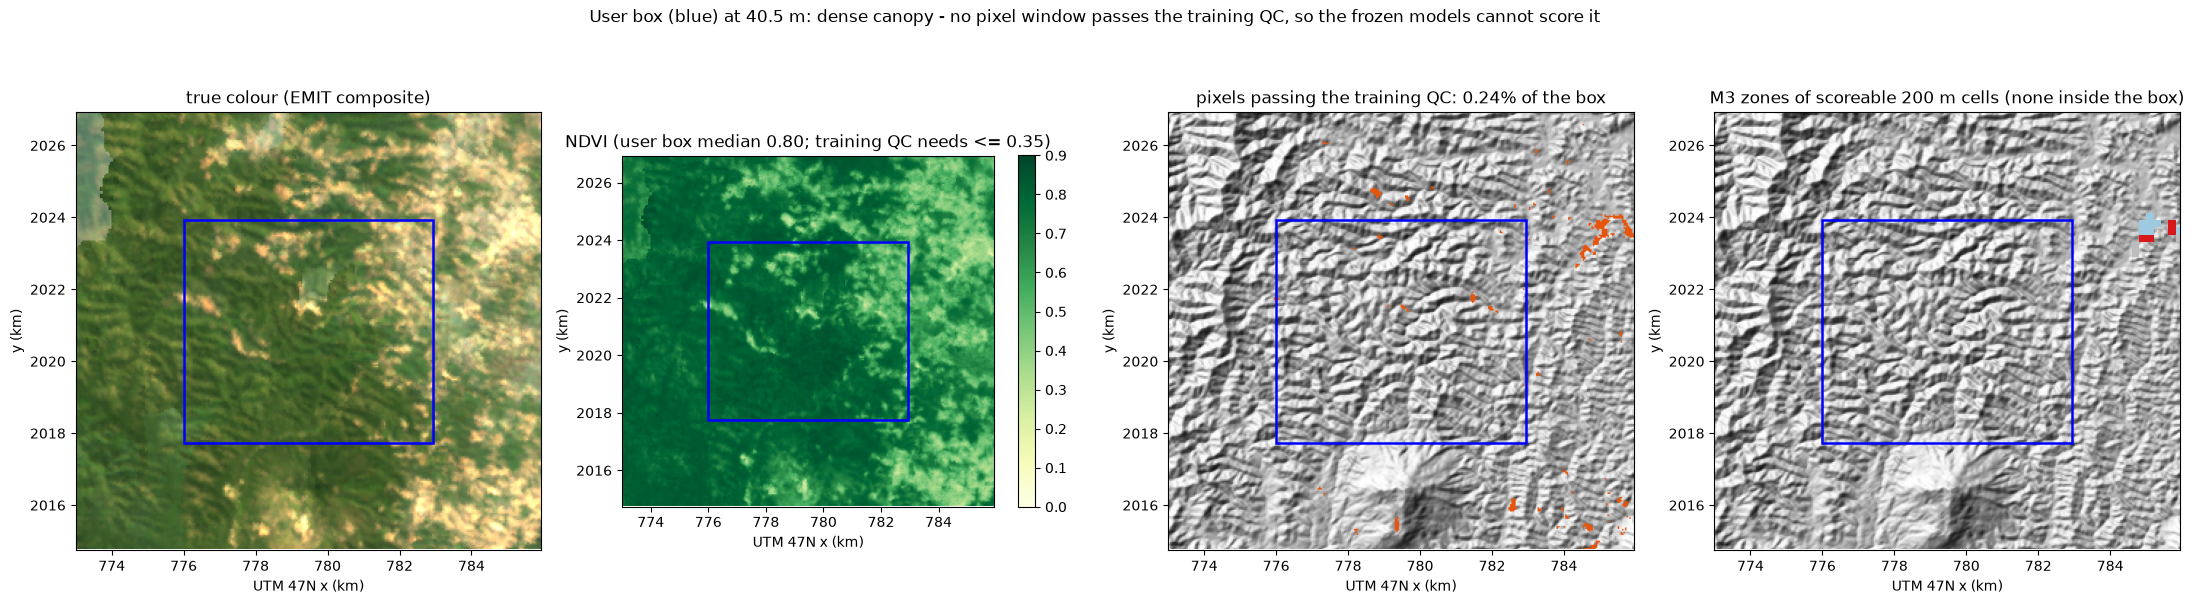

In [16]:
# zoom on the user box (+3 km margin) at 40.5 m: true colour, NDVI, training-QC pixels, and the nearest scored 200 m cells (M3, M2)
ub = lx.USER_BOX; m_ = 3000
box = ((ub["xmin"] - m_) / 1e3, (ub["xmax"] + m_) / 1e3, (ub["ymin"] - m_) / 1e3, (ub["ymax"] + m_) / 1e3)
r0, r1 = int((lx.WINDOW["ymax"] - ub["ymax"] - m_) // lx.RES), int((lx.WINDOW["ymax"] - ub["ymin"] + m_) // lx.RES)
c0, c1 = int((ub["xmin"] - m_ - lx.WINDOW["xmin"]) // lx.RES), int((ub["xmax"] + m_ - lx.WINDOW["xmin"]) // lx.RES)
ext_z = [(lx.WINDOW["xmin"] + c0 * lx.RES) / 1e3, (lx.WINDOW["xmin"] + c1 * lx.RES) / 1e3, (lx.WINDOW["ymax"] - r1 * lx.RES) / 1e3, (lx.WINDOW["ymax"] - r0 * lx.RES) / 1e3]
rgbz = np.stack([np.asarray(F["cube170"][r0:r1, c0:c1, int(np.argmin(np.abs(wl_a - w)))]) for w in (650, 550, 470)], -1)
fig, axs = plt.subplots(1, 4, figsize=(22, 6))
axs[0].imshow(np.clip(rgbz / np.nanpercentile(rgbz, 99), 0, 1), extent=ext_z); axs[0].set_title("true colour (EMIT composite)")
im = axs[1].imshow(PM["NDVI"][r0:r1, c0:c1], extent=ext_z, cmap="YlGn", vmin=0, vmax=.9); plt.colorbar(im, ax=axs[1], shrink=.7)
axs[1].set_title(f"NDVI (user box median {MASKS['ndvi_median_userbox']:.2f}; training QC needs <= 0.35)")
axs[2].imshow(HS[r0:r1, c0:c1], cmap="gray", extent=ext_z, vmin=.1, vmax=1); axs[2].imshow(np.where(qc[r0:r1, c0:c1], 1, np.nan), extent=ext_z, cmap=ListedColormap(["#e6550d"]))
axs[2].set_title(f"pixels passing the training QC: {MASKS['share_userbox_pixel_qc_ok']:.2%} of the box")
zr, off = zone_raster("M3")
axs[3].imshow(HS[r0:r1, c0:c1], cmap="gray", extent=ext_z, vmin=.1, vmax=1); axs[3].imshow(off, extent=EXT5, cmap=ListedColormap(["#9ecae1"]), interpolation="nearest")
axs[3].imshow(zr, extent=EXT5, cmap=ZONE, vmin=0, vmax=2, interpolation="nearest"); axs[3].set_title("M3 zones of scoreable 200 m cells (none inside the box)")
for a in axs: decorate(a, box)
plt.suptitle("User box (blue) at 40.5 m: dense canopy - no pixel window passes the training QC, so the frozen models cannot score it", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, .94]); plt.savefig(OUT / "laos15_zoom_userbox.png", dpi=110); plt.show()

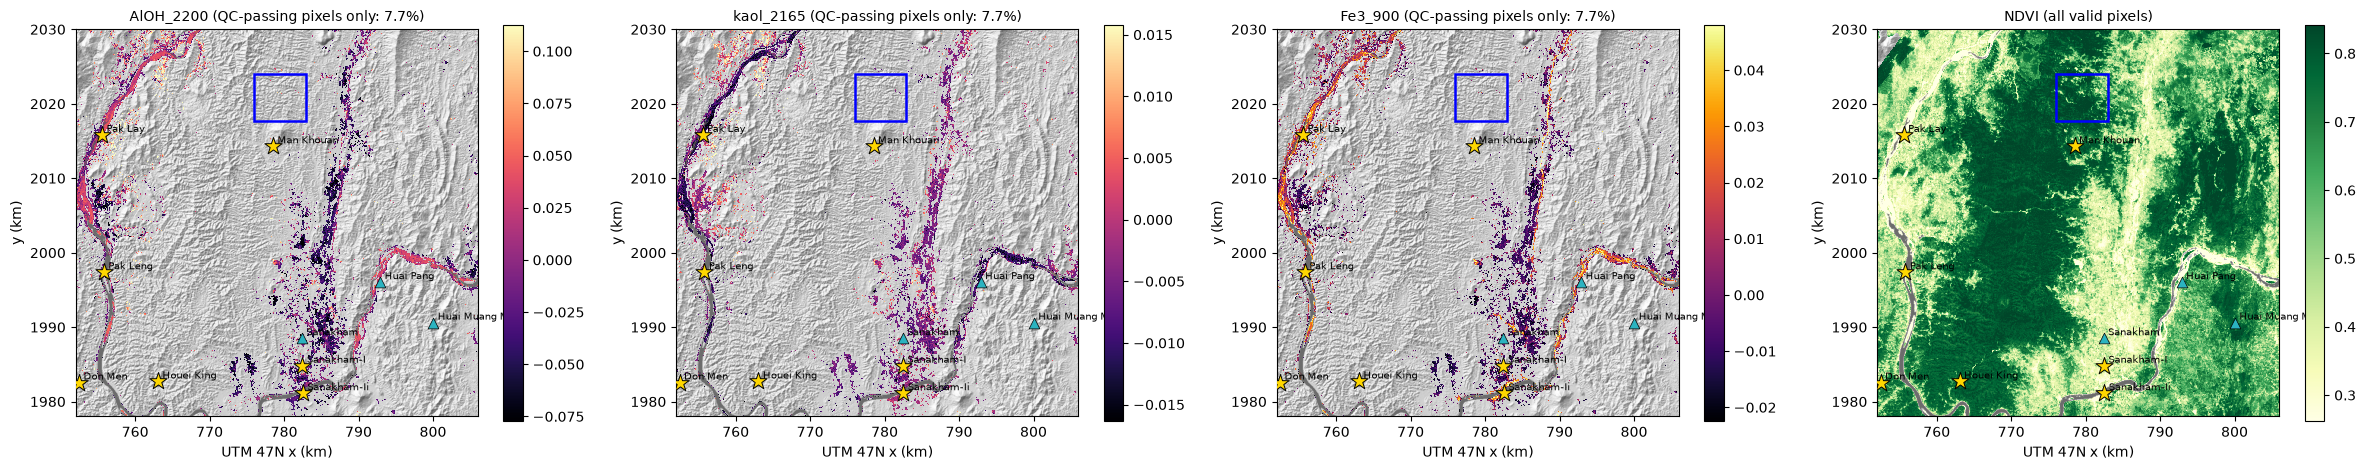

In [17]:
# per-pixel mineral feature maps over the window (NB08 band-depth definitions; NaN where the training QC fails)
fig, axs = plt.subplots(1, 4, figsize=(24, 6.4))
for ax, (k, cm) in zip(axs, [("AlOH_2200", "magma"), ("kaol_2165", "magma"), ("Fe3_900", "inferno"), ("NDVI", "YlGn")]):
    v = PM[k]; lo, hi = np.nanpercentile(v, [2, 98])
    ax.imshow(HS, cmap="gray", extent=EXT, vmin=.1, vmax=1, alpha=.7)
    im = ax.imshow(v, extent=EXT, cmap=cm, vmin=lo, vmax=hi, interpolation="nearest"); plt.colorbar(im, ax=ax, shrink=.65)
    decorate(ax); ax.set_title(f"{k} ({'all valid pixels' if k == 'NDVI' else 'QC-passing pixels only: ' + format(np.isfinite(v).mean(), '.1%')})", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "laos15_mineral_maps.png", dpi=105); plt.show()

In [18]:
# GeoTIFFs (EPSG:32647) for QGIS / Google Earth, and KML of the top-10% cells
for k in MODELS_USED:
    A, T5 = lx.to_raster(L.assign(v=np.where(L.search_scored, L[f"ra_{k}"], np.nan)), "v")
    lx.write_geotiff(OUT / f"laos15_rankarea_{k}_200m.tif", A, T5)
A_all, _ = lx.to_raster(L.assign(v=1.0 * L.search_scored), "v"); lx.write_geotiff(OUT / "laos15_search_scored_200m.tif", np.nan_to_num(A_all).astype("uint8"), T5, nodata=0, dtype="uint8")
code_ = np.zeros((lx.NY, lx.NX), "uint8"); code_[valid] = 1; code_[valid & qc] = 2; code_[water] = 3
lx.write_geotiff(OUT / "laos15_valid_mask_40m.tif", code_, lx.GA, nodata=255, dtype="uint8")
lx.write_geotiff(OUT / "laos15_ndvi_40m.tif", PM["NDVI"], lx.GA)
NPOLY = {}
for k in ["M3", "M2"]:
    A, T5 = lx.to_raster(L.assign(v=1.0 * (L.search_scored & (L[f"ra_{k}"] <= .10))), "v")
    NPOLY[k] = lx.write_kml(OUT / f"laos15_top10_{k}.kml", np.nan_to_num(A).astype(bool), T5, f"Laos15 {k} top 10%",
                            f"Top 10% of the scored search area, frozen Nevada model {k}, EMIT 2025-2026 dry-season composite. Relative rank, not gold probability. "
                            "The user box (white) has no scoreable pixels (dense canopy).")
print("KML polygons:", NPOLY, "| files:", sorted(p.name for p in OUT.glob("laos15_*.tif")) + sorted(p.name for p in OUT.glob("*.kml")))

KML polygons: {'M3': 71, 'M2': 60} | files: ['laos15_ndvi_40m.tif', 'laos15_rankarea_M0_200m.tif', 'laos15_rankarea_M2_200m.tif', 'laos15_rankarea_M3_200m.tif', 'laos15_search_scored_200m.tif', 'laos15_valid_mask_40m.tif', 'laos15_top10_M2.kml', 'laos15_top10_M3.kml']


In [19]:
# tables + summary json
keep = ["id", "set", "x", "y", "lon", "lat", "r", "c", "slope", "elev", "water_share", "dist_water_m", "search", "search_scored", "win_valid_frac"] + COLS61 + \
       [k for k in RANKERS] + [f"ra_{k}" for k in RANKERS]
L[keep].to_csv(OUT / "laos15_scores_grid.csv", index=False)
SUMMARY = {
    "notebook": "15_laos_emit_transfer", "built": time.strftime("%Y-%m-%d %H:%M:%S"),
    "caveat": "Untested transfer of frozen Nevada (AVIRIS) models to tropical Laos with EMIT. Scores are relative ranks within the scored search area, never probabilities of gold. MRDS coordinates are +-1 km and mostly bare occurrences: validation is descriptive.",
    "scenes": {"n_dry_granules": int(len(G)), "selection_rule": ">= 10% of the window clear (MASK aggregate + water + dilated cloud)",
               "granules_used": list(SEL.key), "dates_used": F["meta"]["dates"]},
    "reflectance_qc_composite": QCC, "masks": MASKS, "domain_shift": SHIFT,
    "spearman_shortcut": SC.round(4).to_dict(), "near_water": NEARW, "gold_sites": T_SITES.round(4).to_dict(orient="records"), "recall_descriptive": REC.to_dict(),
    "null_max_in_radius": NULL, "emit_min_crosscheck": MINX.round(4).to_dict(orient="records") if len(MINX) else None,
    "models": {k: NAMES[k] for k in MODELS_USED}, "kml_polygons": NPOLY,
    "not_available": "lithology and stream-sediment geochemistry for Laos -> no lithology matching, no stage B (M4/X1)",
}
(OUT / "laos15_summary.json").write_text(json.dumps(SUMMARY, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o)))
print(f"written {OUT / 'laos15_summary.json'}; total notebook time {time.time() - T0:.0f}s")

written D:\RIFFAI_main\RIFFAI_GOLD\outputs\laos15\laos15_summary.json; total notebook time 53s


## 11. สรุปผล (ตัวเลขจากการรันข้างบน)

**ภาพที่ใช้.** EMIT L2A ฤดูแล้ง (พ.ย.-เม.ย.) เหนือหน้าต่างมี 23 granule (ธ.ค. 2024 - เม.ย. 2026) คัดด้วยกฎ "พื้นที่ฟ้าเปิด >= 10% ของหน้าต่าง"
ได้ **8 granule / 7 วันที่**: 2025-01-22 (94% ของหน้าต่างฟ้าเปิด), 2025-02-14 (2 granule), 2025-03-24, 2026-01-21, 2026-01-25,
2026-04-16, 2026-04-20 ค่าสะท้อนผ่าน QC (0-1; median ที่ 480/660/860/1650/2200/2330 nm = 0.04/0.06/0.27/0.22/0.11/0.07; spike 0%)
composite (median) ครอบคลุม **98.3% ของหน้าต่าง** และ 100% ของกล่องผู้ใช้ ข้อมูลจริงละเอียด 60 m (กริด 40.5 m ใช้เพื่อคงสูตรเดิมเท่านั้น)

**อะไรรอดจาก mask.** หน้าต่าง 2,810 km2 มี NDVI มัธยฐาน 0.64 พิกเซลที่ผ่าน QC แบบตอนฝึก (NDVI <= 0.35, NIR >= 0.05) มีเพียง
**7.7% ของหน้าต่าง** และ **0.24% ของกล่องผู้ใช้** (NDVI มัธยฐานในกล่อง 0.80 = ป่าทึบ/สวน) พื้นที่ค้นหา (ความชัน 5.2-28.3 องศา, ไม่ใช่น้ำ)
= **2,250 km2** (80% ของหน้าต่าง) แต่ในนั้นจุดกริด 200 m ที่ให้คะแนนได้ (หน้าต่าง 11x11 ผ่าน QC >= 30%) มีแค่ **1,146 จุด ≈ 47 km2
(2.1% ของพื้นที่ค้นหา)**; ทั้งหน้าต่างให้คะแนนได้ 6,386 จุด (9.5%) ส่วนใหญ่ (5,240) เป็นที่ราบนอกช่วงความชัน (นา/ไร่ ตลิ่งแม่น้ำ)
**กล่องของผู้ใช้: 0 จาก 26,316 พิกเซล** ให้คะแนนได้ (`win_valid_frac` สูงสุด 0.16) จึงไม่มีแผนที่จัดอันดับในกล่อง และไม่มีโพลิกอน 10% บนในกล่อง

**Domain shift (ข้อสรุปหลัก: ข้อมูลลาวอยู่นอกโดเมนของโมเดลอย่างชัดเจน)**
- 61 feature: การเลื่อนของมัธยฐานเฉลี่ย (|shift| มัธยฐาน) **0.88 sd** ของ Nevada; **13/61 feature** มีมัธยฐานลาวอยู่นอกช่วง 1-99% ของ Nevada;
  เฉลี่ย **24%** ของจุดลาวอยู่นอกช่วงต่อ feature และ **100% ของจุดลาวมีอย่างน้อย 1 feature อยู่นอกช่วง**
- ตัวที่เลื่อนมากที่สุด: ตำแหน่ง absorption (AlOH_pos 2,204 vs 2,195 nm, 99% นอกช่วง; Fe3_pos 937 vs 933 nm; carb_pos), CR-SWIR
  2,107-2,147 nm (ตื้นกว่า) และ 2,356-2,426 nm (ลึกกว่า: ลักษณะของเซลลูโลส/เศษพืชแห้ง หรือขอบสเปกตรัม EMIT), s2_NDVI 0.30 vs 0.14
  (62% เกิน p99 แม้ผ่าน NDVI <= 0.35 แล้ว), s2_clay_B11_B12 1.48 vs 1.16
- PCA ของ 61 feature (fit บน Nevada): กลุ่มจุดลาวแยกออกไปทาง PC2 ติดลบชัดเจน (Mahalanobis เกิน p99 ของ Nevada 9% ในระนาบ 2 มิติ);
  DINOv2 embedding: ลาวเป็นกลุ่มแยกต่างหาก (20% เกิน p99) และ **probe ของ DINOv2 ให้คะแนนลาวมัธยฐาน 0.91 เทียบกับพิกเซล eval ของ Nevada
  -1.43 และจุดทอง Nevada 1.43** = เกือบทุกพิกเซลลาว "ดูเหมือนทอง" ในสายตา probe ซึ่งเป็นอาการของข้อมูลนอกโดเมน ไม่ใช่สัญญาณแร่
- โมเดลไม่เห็นพ้องกัน: Spearman M0-M3 = 0.96 (นอกโดเมน M3 แทบเท่ากับ M0 เพราะ logit ของ baseline ครอบงำการรวม) แต่ **M2 สวนทางกับ
  M0 / M3 (ρ = -0.25 / -0.24)** -> อันดับขึ้นกับว่าเลือกโมเดลไหน ไม่ใช่ข้อมูล
- EMIT L2B MIN (2025-01-22): feature ของเราตรงกับแผนที่แร่ของ EMIT เองบนพิกเซลที่ผ่าน QC (AlOH_2200 AUC 0.83, Fe3_900 AUC 0.83,
  kaol_2165 0.54) แปลว่า band depth คำนวณถูกต้องหลัง resample แต่สิ่งที่ EMIT พบบ่อยที่สุดในกลุ่ม 2 µm คือ "plywood / dry grass"
  (สเปกตรัมคล้ายเศษพืชแห้ง) -> ดินเปลือยในฤดูแล้งของลาวปนเศษพืชมาก

**Shortcut check (จุดในพื้นที่ค้นหาที่ให้คะแนนได้).** Spearman กับ NDVI: M0 0.23, M2 -0.10, M3 0.24; albedo 0.07 / -0.01 / 0.05;
ความชัน -0.13 / 0.09 / -0.13; ความสูง -0.02 / 0.08 / 0.03; ระยะจากน้ำ 0.10 / 0.15 / 0.15 คะแนนไม่ได้เป็นแค่ "ความเปลือย" หรือ "ความสว่าง"
และเซลล์ 10% บนอยู่ใกล้น้ำ (<= 1 km) M0 7%, M2 33%, M3 10% (ฐาน 30%) ต่างจากตัวหลอก NDVI-only ที่ 90% ของ 10% บนคือตลิ่งแม่น้ำ

**จุดทอง MRDS (เชิงพรรณนา n เล็กมาก).** ในหน้าต่างมีแถวทอง 7 แถว (Pak Lay, Don Men, Man Khouan, Sanakham-I = Producer, Sanakham-II,
Pak Leng, Houei King) **Man Khouan และ Houei King (placer) ไม่มีจุดให้คะแนนได้ในรัศมี 1.5 km** (ป่า) เหลือ 5 จุด rank-area ของคะแนนสูงสุด
ในรัศมี 1.5 km:

| จุด | M0 | M2 | M3 | NDVI-only | albedo-only |
|---|---|---|---|---|---|
| Pak Lay | 0.010 | 0.033 | 0.029 | 0.002 | 0.122 |
| Don Men (ขอบหน้าต่าง, 1 จุดในรัศมี) | 0.225 | 0.684 | 0.170 | 0.526 | 0.484 |
| Pak Leng | 0.278 | 0.032 | 0.239 | 0.023 | 0.067 |
| Sanakham-I (Producer) | **0.003** | 0.144 | **0.001** | 0.199 | 0.006 |
| Sanakham-II (placer, ริมโขง) | 0.260 | 0.072 | 0.257 | 0.051 | 0.009 |
| **อยู่ใน 10% บน / 20% บน** | 2/5 / 2/5 | 3/5 / 4/5 | 2/5 / 3/5 | 3/5 / 4/5 | 3/5 / 4/5 |
| ตำแหน่งสุ่ม (null) ที่อยู่ใน 10% บน | 22% | 21% | 22% | 10% | 22% |

ค่าสูงสุดในรัศมี 1.5 km มีอคติเข้าข้างเสมอ (ตำแหน่งสุ่มก็ติด 10% บนราว 21-22%) เมื่อเทียบกับ null แล้ว มัธยฐานของ `null_beats`
(สัดส่วนตำแหน่งสุ่มที่ดีเท่าหรือดีกว่า; 0.5 = โอกาส) คือ M0 0.31, M2 0.17, M3 0.27 แต่ **ตัวหลอก NDVI-only ได้ 0.09 ดีกว่าทุกโมเดล**
เพราะจุดทองส่วนใหญ่ (Pak Lay, Pak Leng, Sanakham-II) อยู่ริมแม่น้ำโขง/ในเมืองที่ดินเปิดโล่ง ไม่ได้บอกอะไรเรื่องการแปรสภาพของหิน
สิ่งเดียวที่น่าสังเกตคือ Sanakham-I (Producer รายเดียว) อยู่ใน 0.1-0.3% บนของ M3 / M0 (`null_beats` 0.02 / 0.03) แต่ตัวหลอก albedo-only ก็ให้
0.006 จึงอธิบายได้ด้วย "พื้นสว่างเปิดโล่ง" (อาจเป็นร่องรอยเหมือง) n = 5 จึง **ไม่คำนวณ bootstrap CI** (ไม่มีความหมาย)
แหล่งแร่อื่นก็ติดอันดับสูงเช่นกัน (Huai Pang แมงกานีส: M2 0.003; Sanakham แกรไฟต์: M3 0.029)

### คำตัดสิน
- **การย้ายโมเดลครั้งนี้ใช้เป็นแผนที่ศักยภาพสำหรับกล่องของผู้ใช้ไม่ได้**: กล่องเป็นป่าทึบ ไม่มีพิกเซลใดอยู่ในโดเมนที่โมเดลรู้จัก
- ส่วนที่ให้คะแนนได้ (≈ 47 km2 ในพื้นที่ค้นหา, 2% ของพื้นที่) อยู่นอกโดเมน Nevada อย่างชัดเจน โมเดลให้อันดับที่ขัดกันเอง และไม่มีโมเดลใด
  ดีกว่าตัวจัดอันดับหลอกจาก NDVI บนจุดทองที่มีอยู่ -> **ผลเป็น null** ซึ่งเป็นคำตอบที่รายงานได้
- สิ่งที่ใช้ได้: pipeline EMIT -> AVIRIS 170 แบนด์ ทำงานถูกต้อง (ค่าสะท้อน 0-1, band depth ตรงกับแผนที่แร่ของ EMIT, AUC 0.83) จึงนำไปใช้กับ
  พื้นที่ดินเปิดโล่ง/แห้งแล้งได้ และแผนที่ AlOH / Fe3+ / kaolinite ใช้ดูเชิงสำรวจบนพื้นที่เปิดโล่งได้
- สำหรับลาว/ไทยที่มีป่าคลุม ควรใช้ข้อมูลที่มองทะลุเรือนยอด/ไม่พึ่งแสง: SAR, DEM + lineament, radiometrics (K/Th/U), ธรณีเคมีตะกอนธารน้ำ
  และถ้าจะใช้ hyperspectral ต้องมีฉลากในพื้นที่เขตร้อนเพื่อฝึก/ทดสอบใหม่ (นอกขอบเขตของ notebook นี้)

> นี่คือการย้ายโมเดลที่ **ยังไม่ผ่านการทดสอบ** และ **ไม่ใช่แผนที่ความน่าจะเป็นที่จะพบทอง**: คะแนนเป็นอันดับสัมพัทธ์ภายในพื้นที่ที่ให้คะแนนได้
> เท่านั้น ฉลากเป็น positive-unlabeled พิกัด MRDS คลาดเคลื่อน ±1 km และเกือบทั้งหมดเป็นแค่ Occurrence

**ส่วนต่างจาก brief:** (1) ใช้ 8 granule / 7 วันที่ตามกฎ >= 10% ฟ้าเปิด (รายการใน brief บางวันมีเมฆเกือบเต็ม เช่น 2024-12-16, 2025-02-18;
granule 2025-01-22 ที่ใช้คือ `_011` ส่วน `_010` อยู่นอกหน้าต่าง) (2) resample สเปกตรัมก่อน ortho/reproject (เป็นการแปลงเชิงเส้น ผลเท่ากัน)
(3) ความชันคำนวณแบบ NB08 บนกริด 90 m จาก GLO-30 เพื่อให้ช่วง 5.2-28.3 องศามีความหมายเดิม (4) จุดทองมี 7 แถว (เพิ่ม Don Men, Gold+Tin
occurrence ที่ขอบตะวันตก) และ Huai Pang เป็นแมงกานีส (ไม่ใช่ "ไม่ทราบ") (5) กล่องผู้ใช้ให้คะแนนไม่ได้ จึงไม่มี GeoTIFF rank-area 40.5 m
ของกล่อง แทนด้วย GeoTIFF NDVI / valid-mask 40.5 m และ KML 10% บนของทั้งหน้าต่าง (M3, M2) (6) เพิ่ม null ของสถิติ "max ในรัศมี 1.5 km"
และตัวหลอก NDVI-only / albedo-only เพื่อให้อ่านผลได้อย่างซื่อตรง

ไฟล์: `outputs/laos15/` (ดู `README.md`), โค้ด `src/laos15.py`, cache `data/raw_ext/emit/<granule>/`, `data/interim/emit_laos_cube_x40.npy`,
`data/interim/laos15_*.{csv,npz,npy}`, `data/processed/patches_laos15/`, `data/processed/dino_emb_laos15.npz`
